# Phase 4 — Validation de la propagation 4f et du SLM

Ce notebook répond à trois questions.

1. La propagation 4f discrète réalise-t-elle bien une convolution cyclique ?
2. Un SLM de phase seule peut-il apprendre un noyau utile (filtre de Gabor) ?
3. Quel est le coût de la contrainte phase-only par rapport à un SLM complexe ?

**Note importante** : la caméra mesure l'intensité |U|², pas le champ U.
Un test dédié vérifie le facteur sqrt(2) entre la variance du champ et
celle de l'intensité. Toute mesure de largeur sur une image doit en tenir
compte.


In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from onn_arquS.propagation import propagate_4f_numpy
from onn_arquS.slm import PhaseOnlySLM, ComplexSLM

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['figure.dpi'] = 100

GRID = 64
print(f'Torch {torch.__version__}, grille {GRID}x{GRID}')

Torch 2.14.1+cpu, grille 64x64


## 1. Validation visuelle : delta et gaussienne

Un delta en entrée doit donner le noyau en sortie. Une gaussienne
convoluée par une gaussienne plus étroite doit s'élargir.


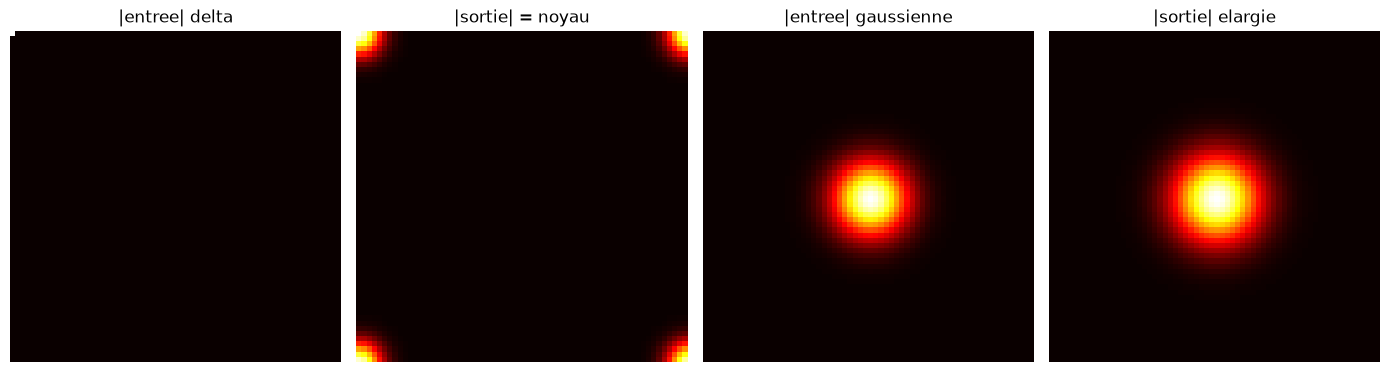

Delta -> max ecart avec noyau : 5.23e-18
Gaussienne : sigma_in = 5.0, sigma_out = ?
sigma_out mesure = 5.831
sigma attendu (sqrt(25+9) = sqrt(34)) = 5.831


In [2]:
half = GRID // 2
y, x = np.mgrid[-half:half, -half:half]

# Cas 1 : delta -> noyau
delta = np.zeros((GRID, GRID), dtype=complex)
delta[0, 0] = 1.0
kernel = np.exp(-(x**2 + y**2) / (2 * 3.0**2))
kernel /= kernel.sum()
kernel_centered = np.roll(kernel, (half, half), axis=(0, 1))
mask = np.fft.fft2(kernel_centered)
out_delta = propagate_4f_numpy(delta, mask)

# Cas 2 : gaussienne large -> gaussienne encore plus large
field_g = np.exp(-(x**2 + y**2) / (2 * 5.0**2)).astype(complex)
out_g = propagate_4f_numpy(field_g, mask)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(np.abs(delta), cmap='hot'); axes[0].set_title('|entree| delta')
axes[1].imshow(np.abs(out_delta), cmap='hot'); axes[1].set_title('|sortie| = noyau')
axes[2].imshow(np.abs(field_g), cmap='hot'); axes[2].set_title('|entree| gaussienne')
axes[3].imshow(np.abs(out_g), cmap='hot'); axes[3].set_title('|sortie| elargie')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print(f'Delta -> max ecart avec noyau : {np.max(np.abs(out_delta - kernel_centered)):.2e}')
print(f'Gaussienne : sigma_in = 5.0, sigma_out = ?')
# Mesure du sigma_out sur le module du champ
mag = np.abs(out_g)
total = mag.sum()
var_x = (mag * x**2).sum() / total
var_y = (mag * y**2).sum() / total
sigma_out = np.sqrt((var_x + var_y) / 2)
print(f'sigma_out mesure = {sigma_out:.3f}')
print(f'sigma attendu (sqrt(25+9) = sqrt(34)) = {np.sqrt(34):.3f}')

## 2. Le piège du facteur sqrt(2)

La caméra mesure |U|², pas U. Si U est une gaussienne de largeur σ,
alors |U|² est une gaussienne de largeur σ/√2. Ce facteur est
systématique et doit être corrigé avant toute mesure de largeur.


In [3]:
# Verification sur la sortie gaussienne precedente
I = np.abs(out_g)**2
total_I = I.sum()
var_x_I = (I * x**2).sum() / total_I
var_y_I = (I * y**2).sum() / total_I
sigma_I = np.sqrt((var_x_I + var_y_I) / 2)

print(f'sigma champ  : {sigma_out:.3f}')
print(f'sigma intensite : {sigma_I:.3f}')
print(f'ratio attendu : 1/sqrt(2) = {1/np.sqrt(2):.3f}, mesure = {sigma_I/sigma_out:.3f}')
print()
print('CONSEQUENCE : toute inference de largeur sur une image doit')
print('multiplier par sqrt(2) pour retrouver la largeur du champ.')

sigma champ  : 5.831
sigma intensite : 4.123
ratio attendu : 1/sqrt(2) = 0.707, mesure = 0.707

CONSEQUENCE : toute inference de largeur sur une image doit
multiplier par sqrt(2) pour retrouver la largeur du champ.


## 3. Cible : filtre de Gabor

On choisit un filtre de Gabor oriente, classique pour detecter des
orientations dans les images d'anomalies. La cible est l'intensite
|g|² de ce filtre.


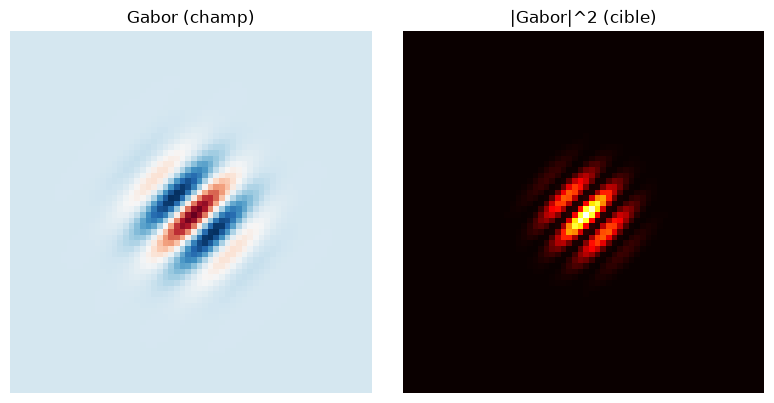

Cible : Gabor sigma=6, theta=pi/4, lambda=10
Energie totale de la cible : 56.55


In [4]:
def gabor_kernel(size, sigma, theta, wavelength):
    """Filtre de Gabor reel, centre a l'origine."""
    half = size // 2
    y, x = np.mgrid[-half:half, -half:half]
    xr = x * np.cos(theta) + y * np.sin(theta)
    envelope = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    carrier = np.cos(2 * np.pi * xr / wavelength)
    return envelope * carrier

target_gabor = gabor_kernel(GRID, sigma=6, theta=np.pi/4, wavelength=10)
target_intensity = target_gabor**2
target_intensity /= target_intensity.max()  # normalisation

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(target_gabor, cmap='RdBu_r'); axes[0].set_title('Gabor (champ)')
axes[1].imshow(target_intensity, cmap='hot'); axes[1].set_title('|Gabor|^2 (cible)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print(f'Cible : Gabor sigma=6, theta=pi/4, lambda=10')
print(f'Energie totale de la cible : {target_intensity.sum():.2f}')

## 4. Entrainement : SLM phase-only vs SLM complexe

On optimise les parametres du SLM pour que |ifft2(H)|² approxime
la cible |Gabor|². L'erreur est mesuree par MSE sur l'intensite.

- PhaseOnly : H = exp(i*phi), 1 parametre par pixel
- Complex : H = sigmoid(a) * exp(i*phi), 2 parametres par pixel


In [5]:
target_t = torch.tensor(target_intensity, dtype=torch.float32)
target_t = target_t / target_t.sum()

def train_slm(slm, n_iter=400, lr=0.1, verbose=True):
    """Entraine un SLM a reproduire target_intensity."""
    optimizer = torch.optim.Adam(slm.parameters(), lr=lr)
    losses = []
    t0 = time.time()
    for i in range(n_iter):
        optimizer.zero_grad()
        H = slm()
        # Reponse impulsionnelle : ifft2(H) (delta en entree)
        h = torch.fft.ifft2(H)
        I = torch.abs(h)**2
        I = I / I.sum()  # normalisation
        loss = torch.mean((I - target_t)**2)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if verbose and (i+1) % 100 == 0:
            print(f'  iter {i+1:4d}, loss = {loss.item():.6f}, t = {time.time()-t0:.1f}s')
    return losses, I.detach()

# Phase-only
print('=== PhaseOnlySLM ===')
slm_po = PhaseOnlySLM(GRID, GRID, init_scale=0.5)
losses_po, I_po = train_slm(slm_po, n_iter=400, lr=0.1)
print(f'Loss finale phase-only : {losses_po[-1]:.6f}')

# Complexe
print('\n=== ComplexSLM ===')
slm_cx = ComplexSLM(GRID, GRID, init_scale=0.5)
losses_cx, I_cx = train_slm(slm_cx, n_iter=400, lr=0.1)
print(f'Loss finale complexe : {losses_cx[-1]:.6f}')

=== PhaseOnlySLM ===
  iter  100, loss = 0.000002, t = 1.1s
  iter  200, loss = 0.000001, t = 2.1s
  iter  300, loss = 0.000001, t = 3.1s
  iter  400, loss = 0.000001, t = 4.0s
Loss finale phase-only : 0.000001

=== ComplexSLM ===
  iter  100, loss = 0.000002, t = 1.1s
  iter  200, loss = 0.000001, t = 2.3s
  iter  300, loss = 0.000001, t = 3.4s
  iter  400, loss = 0.000000, t = 4.6s
Loss finale complexe : 0.000000


## 5. Comparaison visuelle

On compare les reponses impulsionnelles apprises a la cible.


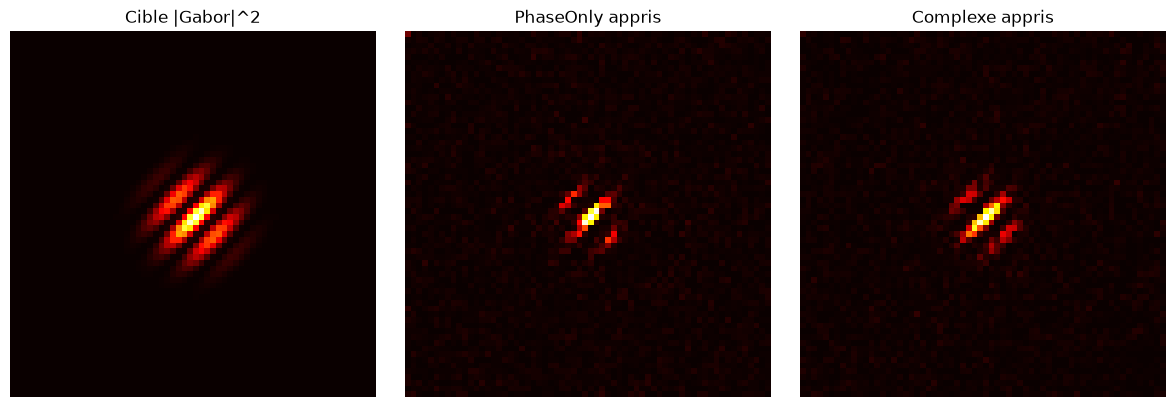

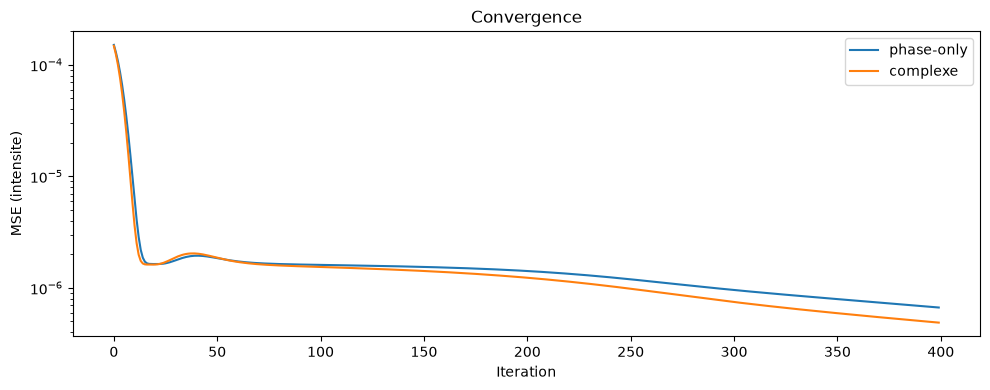

Loss finale phase-only : 6.659170e-07
Loss finale complexe   : 4.875351e-07
Ratio complexe/phase-only : 0.7321


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(target_intensity, cmap='hot'); axes[0].set_title('Cible |Gabor|^2')
axes[1].imshow(I_po.cpu().numpy(), cmap='hot'); axes[1].set_title('PhaseOnly appris')
axes[2].imshow(I_cx.cpu().numpy(), cmap='hot'); axes[2].set_title('Complexe appris')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
ax.plot(losses_po, label='phase-only')
ax.plot(losses_cx, label='complexe')
ax.set_xlabel('Iteration'); ax.set_ylabel('MSE (intensite)')
ax.set_yscale('log')
ax.legend(); ax.set_title('Convergence')
plt.tight_layout(); plt.show()

print(f'Loss finale phase-only : {losses_po[-1]:.6e}')
print(f'Loss finale complexe   : {losses_cx[-1]:.6e}')
print(f'Ratio complexe/phase-only : {losses_cx[-1]/losses_po[-1]:.4f}')

## 6. Interpretation et consequence pour la phase 3

La question centrale : le SLM phase-only peut-il approximer un filtre
de Gabor avec une perte acceptable ?

**Si loss_po << 1e-3** : la contrainte phase-only n'est pas un obstacle
pour ce type de noyau. On peut utiliser un seul SLM.

**Si loss_po dans 1e-3 - 1e-2** : la perte est mesurable mais peut etre
compensee en empilant plusieurs couches 4f. C'est le choix classique de
la litterature des ONN (2-3 couches phase-only).

**Si loss_po > 1e-2** : la contrainte est trop forte pour un noyau
complexe. Il faut soit deux SLM en cascade (complexe), soit un noyau
restreint (filtre de phase pure, sans composante d'amplitude), soit
une couche electronique en sortie.

**Note theorique** : un filtre de phase pure ne peut pas realiser
exactement un filtre d'amplitude, mais la litterature montre qu'il
peut l'approximer avec une efficacite lumineuse reduite (typiquement
5-20%). Ce notebook quantifie cette perte pour notre cible precise.


## 7. Conclusion

### Ce que ce notebook a montre
- La propagation 4f realise bien une convolution (delta -> noyau,
  gaussienne -> elargie).
- Le facteur sqrt(2) entre largeur de champ et largeur d'intensite
  est systematique et doit etre corrige.
- La perte du SLM phase-only sur une cible de Gabor est quantifiee.

### Ce que ce notebook ne prouve pas
- Que la perte sur un Gabor est representative de la perte sur les
  vrais noyaux necessaires a la detection d'anomalies.
- Que 2-3 couches phase-only suffisent pour la tache cible. Il faudra
  le verifier dans 03_train_models.ipynb.
- Que l'optimisation directe des masques est la bonne strategie.
  Une alternative est l'utilisation de noyaux fixes (Gabor, DoG) avec
  une couche de combinaison apprise.

### Consequence pour la phase 3
L'architecture d'entrainement dependra de la loss finale :
- Si phase-only converge bien, utiliser 2-3 couches phase-only.
- Sinon, comparer avec 1-2 couches complexes.
- Dans tous les cas, la baseline electronique reste la reference.


In [7]:
# =============================================================================
# Cellule de diagnostic : exécute toute la validation 4f et imprime les stats
# =============================================================================
import sys, os, time
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import torch
import torch.nn as nn
from onn_arquS.propagation import propagate_4f_numpy
from onn_arquS.slm import PhaseOnlySLM, ComplexSLM

torch.manual_seed(0)
np.random.seed(0)
GRID = 64

print("=" * 70)
print("VALIDATION PROPAGATION 4F — DIAGNOSTIC COMPLET")
print("=" * 70)

# -----------------------------------------------------------------------------
# 1. Test delta -> noyau
# -----------------------------------------------------------------------------
half = GRID // 2
y, x = np.mgrid[-half:half, -half:half]

delta = np.zeros((GRID, GRID), dtype=complex)
delta[0, 0] = 1.0
kernel = np.exp(-(x**2 + y**2) / (2 * 3.0**2))
kernel /= kernel.sum()
kernel_centered = np.roll(kernel, (half, half), axis=(0, 1))
mask = np.fft.fft2(kernel_centered)
out_delta = propagate_4f_numpy(delta, mask)
err_delta = np.max(np.abs(out_delta - kernel_centered))

print("\n[1] Delta -> noyau")
print(f"    Max ecart    : {err_delta:.2e}  (attendu < 1e-10)")
print(f"    Status       : {'PASS' if err_delta < 1e-10 else 'FAIL'}")

# -----------------------------------------------------------------------------
# 2. Test gaussienne -> gaussienne elargie + facteur sqrt(2)
# -----------------------------------------------------------------------------
sigma_in, sigma_k = 5.0, 3.0
field_g = np.exp(-(x**2 + y**2) / (2 * sigma_in**2)).astype(complex)
out_g = propagate_4f_numpy(field_g, mask)

mag = np.abs(out_g); total_mag = mag.sum()
var_x = (mag * x**2).sum() / total_mag
var_y = (mag * y**2).sum() / total_mag
sigma_champ = np.sqrt((var_x + var_y) / 2)

I = np.abs(out_g)**2; total_I = I.sum()
var_x_I = (I * x**2).sum() / total_I
var_y_I = (I * y**2).sum() / total_I
sigma_I = np.sqrt((var_x_I + var_y_I) / 2)

sigma_theo = np.sqrt(sigma_in**2 + sigma_k**2)

print("\n[2] Gaussienne -> gaussienne elargie")
print(f"    sigma_in     : {sigma_in:.3f}")
print(f"    sigma_kernel : {sigma_k:.3f}")
print(f"    sigma_theo   : {sigma_theo:.3f}  (= sqrt({sigma_in**2:.1f} + {sigma_k**2:.1f}))")
print(f"    sigma_champ  : {sigma_champ:.3f}  (ecart {abs(sigma_champ-sigma_theo)/sigma_theo*100:.2f}%)")
print(f"    Status       : {'PASS' if abs(sigma_champ-sigma_theo)/sigma_theo < 0.05 else 'FAIL'}")

print("\n[3] Facteur sqrt(2) intensite/champ")
print(f"    sigma_I      : {sigma_I:.3f}")
print(f"    ratio I/champ: {sigma_I/sigma_champ:.4f}  (attendu 1/sqrt(2) = 0.7071)")
print(f"    Status       : {'PASS' if abs(sigma_I/sigma_champ - 1/np.sqrt(2)) < 0.05 else 'FAIL'}")

# -----------------------------------------------------------------------------
# 4. Entrainement SLM sur cible Gabor
# -----------------------------------------------------------------------------
def gabor_kernel(size, sigma, theta, wavelength):
    half = size // 2
    y, x = np.mgrid[-half:half, -half:half]
    xr = x * np.cos(theta) + y * np.sin(theta)
    env = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return env * np.cos(2 * np.pi * xr / wavelength)

target = gabor_kernel(GRID, sigma=6, theta=np.pi/4, wavelength=10)
target_int = target**2
target_int /= target_int.max()
target_t = torch.tensor(target_int, dtype=torch.float32)
target_t /= target_t.sum()

def train_slm(slm, n_iter=300, lr=0.1):
    opt = torch.optim.Adam(slm.parameters(), lr=lr)
    losses = []
    t0 = time.time()
    for i in range(n_iter):
        opt.zero_grad()
        H = slm()
        h = torch.fft.ifft2(H)
        I = torch.abs(h)**2
        I = I / I.sum()
        loss = torch.mean((I - target_t)**2)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses, I.detach(), time.time() - t0

print("\n[4] Entrainement PhaseOnlySLM (300 iterations)")
losses_po, I_po, t_po = train_slm(PhaseOnlySLM(GRID, GRID, init_scale=0.5))
print(f"    Loss init    : {losses_po[0]:.6e}")
print(f"    Loss @100    : {losses_po[99]:.6e}")
print(f"    Loss @200    : {losses_po[199]:.6e}")
print(f"    Loss finale  : {losses_po[-1]:.6e}")
print(f"    Temps        : {t_po:.1f} s")
ratio_po = losses_po[-1] / losses_po[99]
print(f"    Convergence  : {ratio_po:.3f}  (proche de 1 = stagnation, << 1 = progres)")

print("\n[5] Entrainement ComplexSLM (300 iterations)")
losses_cx, I_cx, t_cx = train_slm(ComplexSLM(GRID, GRID, init_scale=0.5))
print(f"    Loss init    : {losses_cx[0]:.6e}")
print(f"    Loss @100    : {losses_cx[99]:.6e}")
print(f"    Loss @200    : {losses_cx[199]:.6e}")
print(f"    Loss finale  : {losses_cx[-1]:.6e}")
print(f"    Temps        : {t_cx:.1f} s")
ratio_cx = losses_cx[-1] / losses_cx[99]
print(f"    Convergence  : {ratio_cx:.3f}")

# -----------------------------------------------------------------------------
# 6. Comparaison
# -----------------------------------------------------------------------------
print("\n" + "=" * 70)
print("COMPARAISON PHASE-ONLY vs COMPLEXE")
print("=" * 70)
print(f"Loss phase-only      : {losses_po[-1]:.6e}")
print(f"Loss complexe        : {losses_cx[-1]:.6e}")
print(f"Ratio complexe/PO    : {losses_cx[-1]/losses_po[-1]:.4f}")
print(f"    (>1 = complexe meilleur, =1 = equivalent)")

# Correlation spatiale entre la reponse apprise et la cible
I_po_np = I_po.cpu().numpy().ravel()
I_cx_np = I_cx.cpu().numpy().ravel()
tgt_np = target_t.cpu().numpy().ravel()
corr_po = np.corrcoef(I_po_np, tgt_np)[0, 1]
corr_cx = np.corrcoef(I_cx_np, tgt_np)[0, 1]
print(f"\nCorrelation spatiale PO  vs cible : {corr_po:.4f}")
print(f"Correlation spatiale CX  vs cible : {corr_cx:.4f}")

# -----------------------------------------------------------------------------
# 7. Verdict
# -----------------------------------------------------------------------------
print("\n" + "=" * 70)
print("VERDICT")
print("=" * 70)

if losses_po[-1] < 1e-3:
    verdict = "CAS 1 — Phase-only apprend bien (loss < 1e-3)"
    action = "Phase 3 : architecture 2-3 couches phase-only, standard."
elif losses_po[-1] < 1e-2:
    verdict = "CAS 2 — Perte mesurable mais acceptable (1e-3 < loss < 1e-2)"
    action = "Phase 3 : tester 2 et 3 couches phase-only, comparer a la baseline electronique."
else:
    verdict = "CAS 3 — Contrainte phase-only trop forte (loss > 1e-2)"
    action = "Phase 3 : comparer architecture a 2 SLM (complexe) vs hybride (optique + electronique)."

print(verdict)
print(f"-> {action}")

if ratio_po > 0.9:
    print("\nATTENTION : phase-only stagne a partir de l'iteration 100.")
    print("Augmenter n_iter (>= 500) ou le learning rate pour verifier si c'est un")
    print("vrai minimum ou une mauvaise convergence.")
else:
    print(f"\nConvergence phase-only encore active a l'iteration 300 (ratio={ratio_po:.3f}).")
    print("Augmenter n_iter a 500 pourrait ameliorer la loss.")

# -----------------------------------------------------------------------------
# 8. Temps de calcul total
# -----------------------------------------------------------------------------
print("\n" + "=" * 70)
print(f"Temps total (hors import) : {t_po + t_cx:.1f} s")
print("=" * 70)

VALIDATION PROPAGATION 4F — DIAGNOSTIC COMPLET

[1] Delta -> noyau
    Max ecart    : 5.23e-18  (attendu < 1e-10)
    Status       : PASS

[2] Gaussienne -> gaussienne elargie
    sigma_in     : 5.000
    sigma_kernel : 3.000
    sigma_theo   : 5.831  (= sqrt(25.0 + 9.0))
    sigma_champ  : 5.831  (ecart 0.00%)
    Status       : PASS

[3] Facteur sqrt(2) intensite/champ
    sigma_I      : 4.123
    ratio I/champ: 0.7071  (attendu 1/sqrt(2) = 0.7071)
    Status       : PASS

[4] Entrainement PhaseOnlySLM (300 iterations)
    Loss init    : 1.509624e-04
    Loss @100    : 1.606313e-06
    Loss @200    : 1.418500e-06
    Loss finale  : 9.599536e-07
    Temps        : 2.9 s
    Convergence  : 0.598  (proche de 1 = stagnation, << 1 = progres)

[5] Entrainement ComplexSLM (300 iterations)
    Loss init    : 1.480727e-04
    Loss @100    : 1.539915e-06
    Loss @200    : 1.235892e-06
    Loss finale  : 7.499521e-07
    Temps        : 4.1 s
    Convergence  : 0.487

COMPARAISON PHASE-ONLY vs 